---
title: "Model Inference on Custom Dataset"
---

## Laboratory Exercise — Model Inference on Custom Dataset

**Goal.** Fine-tune an ImageNet-pretrained ResNet-50 on a custom image dataset (150 Pokémon
classes) with PyTorch Lightning. Then use the saved model the way you would after deployment:
load the checkpoint from disk and predict on images it never saw during training or model
selection.

**Dataset.** [Pokémon Image Dataset](https://www.kaggle.com/datasets/lantian773030/pokemonclassification)
by Lance Zhang on Kaggle: 6,820 hand-cropped images in one folder per Pokémon. Download it and place
the `PokemonData` folder at `data/archive/PokemonData` next to this notebook.

**Changes to the provided starter code.** The training logic (`PokeClassifier`, callbacks,
logger, trainer settings) is unchanged. These fixes were needed to make the notebook run
correctly and make inference reliable:

| # | Starter code | Problem | Fix |
|---|---|---|---|
| 1 | `F.softmax` in `predict_step` | `F` was never imported, so inference crashes with `NameError` | `import torch.nn.functional as F` |
| 2 | `class_map` built from `set(...)` | Python randomises string hashing per process, so class indices change between sessions and a saved checkpoint can't be mapped back to names | `sorted(set(...))` |
| 3 | `cv2.imread` + `ToTensor` only | OpenCV loads **BGR**, and the pretrained weights expect **RGB** normalised with ImageNet statistics | PIL `.convert("RGB")` + `T.Normalize` |
| 4 | `random_split` without a generator | A different split every run, so "test" images can leak into training on a re-run | seeded `torch.Generator` |
| 5 | `torch.hub.load('pytorch/vision', ...)` | Downloads code from GitHub's `main` branch at run time | `torchvision.models.resnet50` with the same `IMAGENET1K_V2` weights |
| 6 | Only `.jpg` / `.png` | 40 `.jpeg` images silently dropped | also accept `.jpeg` |
| 7 | `precision="16-mixed"` on any GPU | Mixed precision only pays off on tensor-core GPUs (compute capability ≥ 7.0) | fall back to 32-bit on older GPUs |
| 8 | Images decoded every epoch | Some source images are 5,000 px wide; re-decoding them every epoch made data loading the bottleneck (several minutes per epoch here) | cache each preprocessed tensor after first use (no augmentation, so results are unchanged) |

### Imports

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F          # used by predict_step (missing in the starter)
import torchvision
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms as T
from torchvision.models import resnet50, ResNet50_Weights

# Windows notebooks must use num_workers=0 (notebook-defined classes can't be sent to worker
# processes), so Lightning's "few workers" hint is expected here.
warnings.filterwarnings("ignore", ".*does not have many workers.*")

SEED = 42
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| GPU:",
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)")

torch 2.7.1+cu118 | torchvision 0.22.1+cu118 | GPU: GeForce GTX 1060


### Parse Dataset Directory

In [2]:
root = 'data/archive/PokemonData'

data_dict = {'pokemon_path': [], 'pokemon_name': []}

# sorted() so the file order (and therefore the split) is identical on every machine
for pokemon_fldr in sorted(os.listdir(root)):
    pokemon_path = os.path.join(root, pokemon_fldr)
    for instance in sorted(os.listdir(pokemon_path)):
        instance_path = os.path.join(pokemon_path, instance)
        if instance_path.lower().endswith(('.jpg', '.jpeg', '.png')):
            data_dict['pokemon_path'].append(instance_path)
            data_dict['pokemon_name'].append(pokemon_fldr)

counts = pd.Series(data_dict['pokemon_name']).value_counts()
print(f"{len(data_dict['pokemon_path'])} images across {len(counts)} classes")
print(f"images per class: min {counts.min()} ({counts.idxmin()}), "
      f"median {int(counts.median())}, max {counts.max()} ({counts.idxmax()})")

6820 images across 150 classes
images per class: min 26 (Alakazam), median 46, max 66 (Venusaur)


### Create Custom Dataset Class

In [3]:
class PokeDataset(Dataset):
    def __init__(self, data_dict: dict, transforms=None):
        self.data_dict = data_dict
        self.transforms = transforms
        # sorted() -> the same name->index mapping in every Python session
        self.classes = sorted(set(data_dict['pokemon_name']))
        self.class_map = {p: i for i, p in enumerate(self.classes)}
        # ponytail: caches the final tensor (~1.8 GB for all images); move the cache in front
        # of any random augmentation if you add one, or every epoch would see the same crop.
        self.cache = {}

    def __getitem__(self, idx):
        img = self.data_dict['pokemon_path'][idx]
        lbl = self.class_map[self.data_dict['pokemon_name'][idx]]
        if idx not in self.cache:                     # decode + resize once, reuse every epoch
            image = Image.open(img).convert('RGB')    # RGB; also handles RGBA, palette, grayscale
            self.cache[idx] = self.transforms(image) if self.transforms else image
        label = torch.tensor(lbl, dtype=torch.long)
        return self.cache[idx], label

    def __len__(self):
        return len(self.data_dict['pokemon_name'])

### Dataset Creation and Transformation

In [4]:
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

transforms = T.Compose([
    T.Resize((150, 150)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),   # the statistics the pretrained weights expect
])

pokedataset = PokeDataset(data_dict, transforms)

split_gen = torch.Generator().manual_seed(SEED)   # identical split on every run
train_set, valid_set, test_set = random_split(pokedataset, [0.7, 0.2, 0.1], generator=split_gen)
print(f"train {len(train_set)} | validation {len(valid_set)} | test {len(test_set)}")

train 4774 | validation 1364 | test 682


### DataLoaders

In [5]:
batch = 16

train_loader = DataLoader(train_set, batch, shuffle=True)
valid_loader = DataLoader(valid_set, batch, shuffle=False)
test_loader = DataLoader(test_set, batch, shuffle=False)

### Lightning Module (as provided)

In [6]:
import pytorch_lightning as pl
from torchmetrics import MetricCollection
from torchmetrics.classification import (
    MulticlassAccuracy,
    MulticlassF1Score,
    MulticlassPrecision,
    MulticlassRecall,
    MulticlassConfusionMatrix,
)


class PokeClassifier(pl.LightningModule):
    """
    Wraps any classification model (e.g. a torch.hub ResNet with a new `fc` head)
    with training, validation, testing and prediction logic plus metrics.
    """

    def __init__(
        self,
        model: nn.Module,
        num_classes: int,
        lr: float = 1e-3,
        weight_decay: float = 1e-4,
        label_smoothing: float = 0.1,
        freeze_backbone: bool = False,
        head_name: str = "fc",
    ):
        super().__init__()
        # Don't store the whole model in hparams (it is saved in the checkpoint anyway)
        self.save_hyperparameters(ignore=["model"])
        self.model = model
        self.criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)

        if freeze_backbone:
            self.set_backbone_trainable(False)

        # Metrics: one copy per stage so their states don't mix
        def make_metrics(prefix):
            metrics = {
                "acc": MulticlassAccuracy(num_classes=num_classes, average="micro"),
                "macro_acc": MulticlassAccuracy(num_classes=num_classes, average="macro"),
                "f1": MulticlassF1Score(num_classes=num_classes, average="macro"),
                "precision": MulticlassPrecision(num_classes=num_classes, average="macro"),
                "recall": MulticlassRecall(num_classes=num_classes, average="macro"),
            }
            if num_classes >= 5:
                metrics["top5_acc"] = MulticlassAccuracy(
                    num_classes=num_classes, top_k=5, average="micro"
                )
            return MetricCollection(metrics, prefix=prefix)

        self.train_metrics = make_metrics("train/")
        self.val_metrics = make_metrics("val/")
        self.test_metrics = make_metrics("test/")
        self.test_confmat = MulticlassConfusionMatrix(num_classes=num_classes)

    # ------------------------------------------------------------------ helpers
    def set_backbone_trainable(self, trainable: bool):
        """Freeze/unfreeze everything except the classification head."""
        for name, p in self.model.named_parameters():
            if not name.startswith(self.hparams.head_name + "."):
                p.requires_grad = trainable

    def forward(self, x):
        return self.model(x)

    def _shared_step(self, batch):
        x, y = batch
        # CrossEntropyLoss and torchmetrics need integer class indices (LongTensor).
        if y.ndim > 1:          # one-hot / multi-column labels -> class index
            y = y.argmax(dim=1)
        y = y.long()            # float labels like 3.0 -> 3
        logits = self(x)
        loss = self.criterion(logits, y)
        return loss, logits, y

    # ----------------------------------------------------------------- training
    def training_step(self, batch, batch_idx):
        loss, logits, y = self._shared_step(batch)
        self.train_metrics.update(logits, y)
        self.log("train/loss", loss, on_step=True, on_epoch=True, prog_bar=True)
        return loss

    def on_train_epoch_end(self):
        self.log_dict(self.train_metrics.compute())
        self.train_metrics.reset()

    # --------------------------------------------------------------- validation
    def validation_step(self, batch, batch_idx):
        loss, logits, y = self._shared_step(batch)
        self.val_metrics.update(logits, y)
        self.log("val/loss", loss, on_epoch=True, prog_bar=True)

    def on_validation_epoch_end(self):
        metrics = self.val_metrics.compute()
        # Log val/acc once (with prog_bar), and everything else via log_dict.
        # Logging the same key twice with different args is not allowed.
        self.log("val/acc", metrics.pop("val/acc"), prog_bar=True)
        self.log_dict(metrics)
        self.val_metrics.reset()

    # ------------------------------------------------------------------ testing
    def test_step(self, batch, batch_idx):
        loss, logits, y = self._shared_step(batch)
        self.test_metrics.update(logits, y)
        self.test_confmat.update(logits, y)
        self.log("test/loss", loss, on_epoch=True)

    def on_test_epoch_end(self):
        self.log_dict(self.test_metrics.compute())
        # Keep the confusion matrix around so you can plot it after trainer.test()
        self.confusion_matrix = self.test_confmat.compute().cpu()
        self.test_metrics.reset()
        self.test_confmat.reset()

    # --------------------------------------------------------------- prediction
    def predict_step(self, batch, batch_idx):
        x = batch[0] if isinstance(batch, (list, tuple)) else batch
        probs = F.softmax(self(x), dim=1)
        conf, preds = probs.max(dim=1)
        return {"preds": preds, "confidence": conf, "probs": probs}

    # ---------------------------------------------------------------- optimizer
    def configure_optimizers(self):
        params = [p for p in self.parameters() if p.requires_grad]
        optimizer = torch.optim.AdamW(
            params, lr=self.hparams.lr, weight_decay=self.hparams.weight_decay
        )
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=self.trainer.max_epochs
        )
        return {
            "optimizer": optimizer,
            "lr_scheduler": {"scheduler": scheduler, "interval": "epoch"},
        }

### Model: ImageNet-pretrained ResNet-50 with a new 150-way head

In [7]:
pl.seed_everything(SEED, workers=True)
num_classes = len(pokedataset.class_map)

# Same architecture and weights as torch.hub.load('pytorch/vision', 'resnet50', weights='IMAGENET1K_V2')
model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
model.fc = nn.Linear(model.fc.in_features, num_classes)
print(f"{num_classes} classes | {sum(p.numel() for p in model.parameters()):,} parameters")

Seed set to 42


150 classes | 23,815,382 parameters


### Training, checkpointing and testing

In [8]:
import pandas as pd
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping, LearningRateMonitor
from pytorch_lightning.loggers import CSVLogger

# --- your existing setup ---
# num_classes = len(pokedataset.class_map.keys())
# model = torch.hub.load('pytorch/vision', 'resnet50', weights='IMAGENET1K_V2')
# model.fc = nn.Linear(model.fc.in_features, num_classes)
# train_loader, val_loader, test_loader = ...

lit_model = PokeClassifier(model, num_classes=num_classes, lr=1e-3)

callbacks = [
    ModelCheckpoint(monitor="val/acc", mode="max", save_top_k=1,
                    filename="best-{epoch:02d}-{val/acc:.3f}",
                    auto_insert_metric_name=False),
    EarlyStopping(monitor="val/loss", mode="min", patience=5),
    LearningRateMonitor(logging_interval="epoch"),
]

# Logs go to: logs/poke_resnet50/version_N/metrics.csv (+ hparams.yaml)
csv_logger = CSVLogger(save_dir="logs", name="poke_resnet50")

trainer = pl.Trainer(
    max_epochs=20,
    accelerator="auto",
    devices="auto",
    # tensor cores (compute capability >= 7.0) are where 16-bit pays off
    precision="16-mixed" if torch.cuda.is_available()
              and torch.cuda.get_device_capability()[0] >= 7 else 32,
    enable_progress_bar=False,  # keeps the saved notebook readable
    callbacks=callbacks,
    logger=csv_logger,          # replaces the default TensorBoard logger
    log_every_n_steps=10,
)

trainer.fit(lit_model, train_loader, valid_loader)
trainer.test(lit_model, test_loader, ckpt_path="best")

print(lit_model.confusion_matrix)

# ---- reading the CSV back ----
# metrics.csv mixes step rows and epoch rows (blank cells where a metric wasn't
# logged), so collapse it to one row per epoch.
metrics = pd.read_csv(f"{csv_logger.log_dir}/metrics.csv")
per_epoch = metrics.groupby("epoch").mean(numeric_only=True)
print(per_epoch[["train/loss_epoch", "val/loss", "train/acc", "val/acc", "val/f1"]])

# Save the confusion matrix next to the logs too
pd.DataFrame(lit_model.confusion_matrix.numpy()).to_csv(
    f"{csv_logger.log_dir}/confusion_matrix.csv", index=False
)

GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]



  | Name          | Type                      | Params | Mode  | FLOPs
----------------------------------------------------------------------------
0 | model         | ResNet                    | 23.8 M | train | 0    
1 | criterion     | CrossEntropyLoss          | 0      | train | 0    
2 | train_metrics | MetricCollection          | 0      | train | 0    
3 | val_metrics   | MetricCollection          | 0      | train | 0    
4 | test_metrics  | MetricCollection          | 0      | train | 0    
5 | test_confmat  | MulticlassConfusionMatrix | 0      | train | 0    
----------------------------------------------------------------------------
23.8 M    Trainable params
0         Non-trainable params
23.8 M    Total params
95.262    Total estimated model params size (MB)
174       Modules in train mode
0         Modules in eval mode
0         Total Flops


`Trainer.fit` stopped: `max_epochs=20` reached.


Restoring states from the checkpoint path at logs\poke_resnet50\version_0\checkpoints\best-15-0.957.ckpt


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Loaded model weights from the checkpoint at logs\poke_resnet50\version_0\checkpoints\best-15-0.957.ckpt


────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
       Test metric             DataLoader 0
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
        test/acc            0.9457477927207947
         test/f1            0.9414841532707214
        test/loss           1.1453371047973633
     test/macro_acc          0.950359046459198
     test/precision         0.9476512670516968
       test/recall           0.950359046459198
      test/top5_acc         0.9457477927207947
────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────
tensor([[4, 0, 0,  ..., 0, 0, 0],
        [0, 3, 0,  ..., 0, 0, 0],
        [0, 0, 0,  ..., 0, 0, 0],
        ...,
        [0, 0, 0,  ..., 7, 0, 0],
        [0, 0, 0,  ..., 0, 7, 0],
        [0, 0, 0,  ..., 0, 0, 6]])
       train/loss_epoch  val/loss  train/acc  

### Training curves

`metrics.csv` mixes per-step and per-epoch rows, so the cell above collapses it to one row per
epoch. Training metrics are averaged over each epoch while the weights are still changing.
Validation metrics are computed once at the end of the epoch.

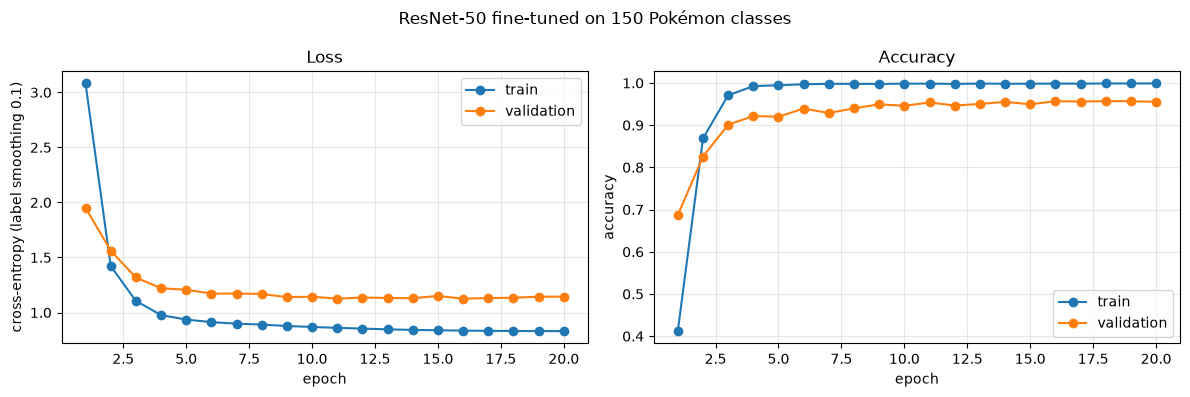

best validation accuracy 0.9567 at epoch 16 of 20 epochs run


In [9]:
per_epoch = per_epoch.dropna(subset=["val/loss"])   # drop the row trainer.test() appends
ep = per_epoch.index.astype(int) + 1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ep, per_epoch["train/loss_epoch"], marker="o", label="train")
axes[0].plot(ep, per_epoch["val/loss"], marker="o", label="validation")
axes[0].set(xlabel="epoch", ylabel="cross-entropy (label smoothing 0.1)", title="Loss")
axes[1].plot(ep, per_epoch["train/acc"], marker="o", label="train")
axes[1].plot(ep, per_epoch["val/acc"], marker="o", label="validation")
axes[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle("ResNet-50 fine-tuned on 150 Pokémon classes")
plt.tight_layout()
plt.show()

best = int(per_epoch["val/acc"].idxmax())
print(f"best validation accuracy {per_epoch['val/acc'].max():.4f} at epoch {best + 1} "
      f"of {len(per_epoch)} epochs run")

## Inference on unseen images

This part treats the model as if it had been shipped. It rebuilds the architecture, loads the
**best checkpoint from disk** (chosen by validation accuracy), and predicts on the 10% test split.
The test images were used neither for training nor for picking the checkpoint.

In [10]:
best_path = trainer.checkpoint_callback.best_model_path
print("best checkpoint:", os.path.relpath(best_path))

backbone = resnet50(weights=None)                      # architecture only; weights come from the checkpoint
backbone.fc = nn.Linear(backbone.fc.in_features, num_classes)
infer_model = PokeClassifier.load_from_checkpoint(best_path, model=backbone)
infer_model.eval()

idx_to_name = {i: name for name, i in pokedataset.class_map.items()}

predictions = trainer.predict(infer_model, test_loader)
preds = torch.cat([p["preds"] for p in predictions]).cpu()
conf = torch.cat([p["confidence"] for p in predictions]).cpu()
labels = torch.tensor([pokedataset.class_map[data_dict['pokemon_name'][i]] for i in test_set.indices])

correct = preds == labels
print(f"test accuracy: {correct.float().mean():.4f} "
      f"({int(correct.sum())}/{len(labels)} unseen images)")
print(f"mean confidence when right: {conf[correct].mean():.3f} | when wrong: {conf[~correct].mean():.3f}")

best checkpoint: logs\poke_resnet50\version_0\checkpoints\best-15-0.957.ckpt


LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


test accuracy: 0.9457 (645/682 unseen images)
mean confidence when right: 0.760 | when wrong: 0.307


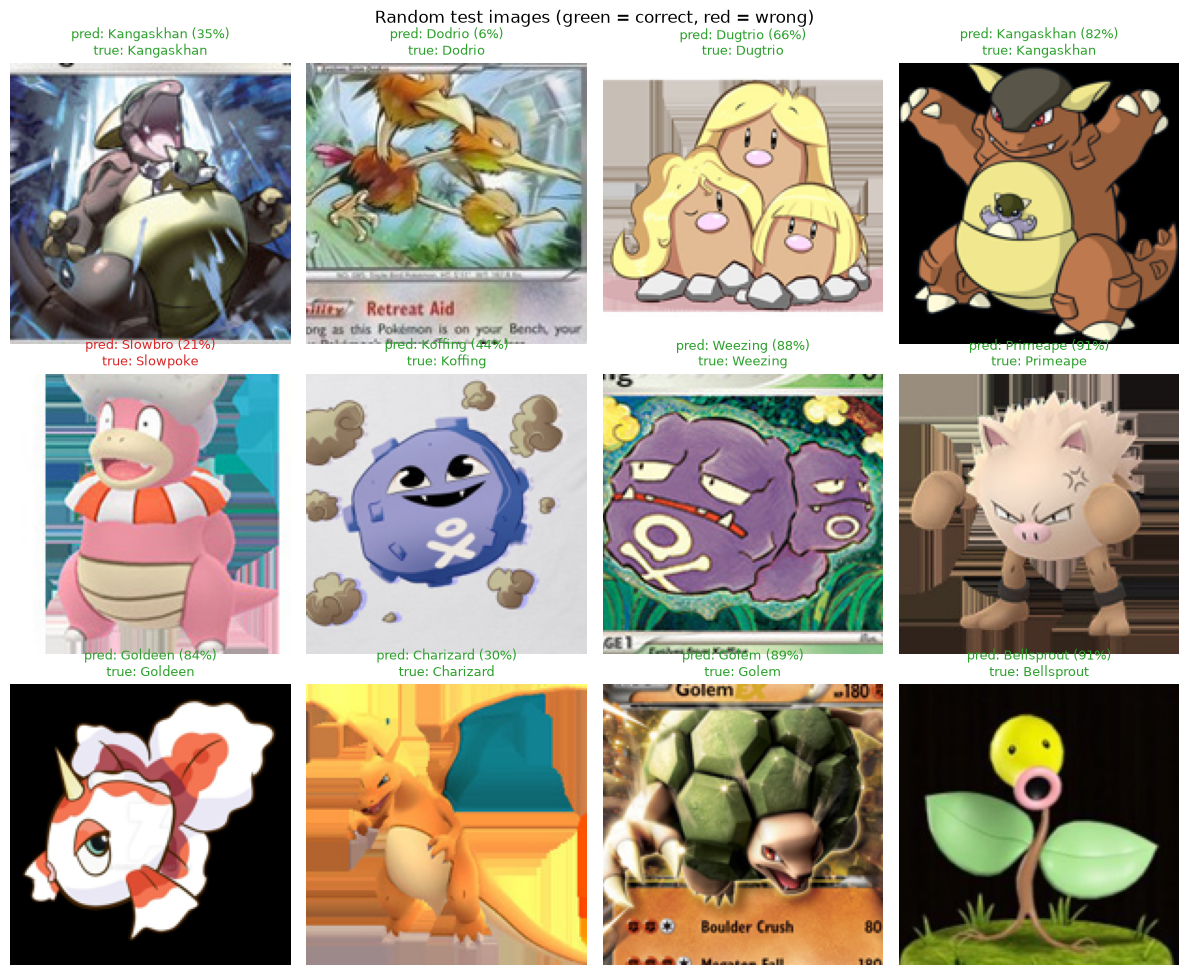

In [11]:
def show_predictions(positions, title, ncols=4):
    nrows = int(np.ceil(len(positions) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3.3 * nrows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, k in zip(np.ravel(axes), positions):
        path = data_dict['pokemon_path'][test_set.indices[k]]
        ax.imshow(Image.open(path).convert("RGB").resize((150, 150)))
        p, t = preds[k].item(), labels[k].item()
        ax.set_title(f"pred: {idx_to_name[p]} ({conf[k]:.0%})\ntrue: {idx_to_name[t]}",
                     color="tab:green" if p == t else "tab:red", fontsize=9)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(SEED)
show_predictions(rng.choice(len(test_set), size=12, replace=False),
                 "Random test images (green = correct, red = wrong)")

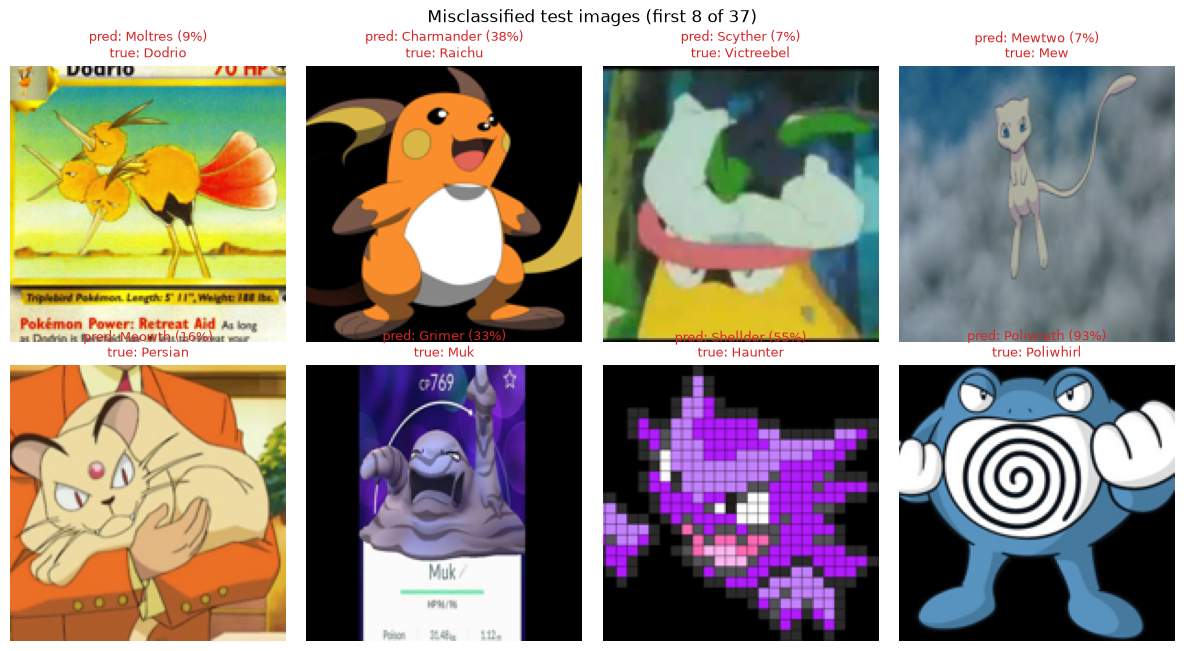

In [12]:
wrong = torch.nonzero(~correct).flatten().tolist()
show_predictions(wrong[:8], f"Misclassified test images (first {min(8, len(wrong))} of {len(wrong)})")

In [13]:
cm = lit_model.confusion_matrix                     # rows = true class, columns = predicted
support = cm.sum(dim=1)
per_class = pd.DataFrame({
    "class": [idx_to_name[i] for i in range(num_classes)],
    "test images": support.numpy(),
    "recall": (cm.diag() / support.clamp(min=1)).numpy(),
})
print("Lowest per-class recall on the test split (classes with >= 3 test images):")
print(per_class[per_class["test images"] >= 3].nsmallest(8, "recall").to_string(index=False))

pairs = pd.Series([f"{idx_to_name[labels[i].item()]} -> {idx_to_name[preds[i].item()]}"
                   for i in wrong]).value_counts()
print("\nMost frequent confusions (true -> predicted):")
print(pairs.head(8).to_string())

Lowest per-class recall on the test split (classes with >= 3 test images):
    class  test images   recall
  Venonat            4 0.500000
Poliwhirl            3 0.666667
 Raticate            3 0.666667
   Weedle            6 0.666667
   Lapras            7 0.714286
   Grimer            4 0.750000
Ninetales            4 0.750000
  Persian            4 0.750000

Most frequent confusions (true -> predicted):
Mankey -> Primeape       2
Dodrio -> Moltres        1
Raichu -> Charmander     1
Victreebel -> Scyther    1
Mew -> Mewtwo            1
Persian -> Meowth        1
Muk -> Grimer            1
Haunter -> Shellder      1


### Predicting a single custom image

`predict_image` is all that's needed to use the model on any new picture. It applies exactly
the preprocessing used in training (resize to 150×150, ImageNet normalisation) and returns the
top-k classes with their softmax probabilities. Point it at your own file, e.g.
`predict_image("my_pikachu.png")`. Below it runs on two test-split files.

In [14]:
device = "cuda" if torch.cuda.is_available() else "cpu"
infer_model.to(device)

@torch.no_grad()
def predict_image(path, top_k=3):
    image = Image.open(path).convert("RGB")
    x = transforms(image).unsqueeze(0).to(device)     # same preprocessing as training
    probs = F.softmax(infer_model(x), dim=1)[0]
    top = probs.topk(top_k)
    return [(idx_to_name[i.item()], round(p.item(), 4)) for p, i in zip(top.values, top.indices)]


examples = [torch.nonzero(correct)[0].item()] + wrong[:1]   # one hit, one miss
for k in examples:
    path = data_dict['pokemon_path'][test_set.indices[k]]
    print(os.path.relpath(path, root), "->", predict_image(path))

Pidgey\53891a1ed4984b29a4fb8b8c890441b8.jpg -> [('Pidgey', 0.9166), ('Raticate', 0.0018), ('Doduo', 0.0016)]
Dodrio\51263687a3904ec88be04ff39a57c781.jpg -> [('Moltres', 0.0926), ('Dodrio', 0.0489), ('Ninetales', 0.0447)]


### Checking the reported top-5 accuracy

The table printed by `trainer.test()` reports `test/top5_acc = 0.9457`, exactly the top-1
accuracy. That can't be right. The misclassified Dodrio image above has its true class ranked
second, so it counts for top-5 but not for top-1. The cell below re-scores the saved checkpoint
on its own: it rebuilds the same seeded split and loads the weights from disk, without using any
earlier cell. It was executed separately after the main run, which is why its execution count
restarts. Outside the training run, torchmetrics gives the correct top-5 value. I could not
reproduce the wrong value, so the cause inside the training run is not pinned down. The top-5
figure to trust is the one below.

In [1]:
# Self-contained: re-score the best checkpoint on the test split without any earlier cell's state.
import glob, os
import torch, torch.nn as nn
from PIL import Image
from torch.utils.data import random_split
from torchvision import transforms as T
from torchvision.models import resnet50
from torchmetrics.classification import MulticlassAccuracy

root = "data/archive/PokemonData"
paths, names = [], []
for d in sorted(os.listdir(root)):
    for f in sorted(os.listdir(os.path.join(root, d))):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(os.path.join(root, d, f)); names.append(d)
classes = sorted(set(names)); class_map = {c: i for i, c in enumerate(classes)}
_, _, test_split = random_split(range(len(paths)), [0.7, 0.2, 0.1],
                                generator=torch.Generator().manual_seed(42))   # same split as above
tf = T.Compose([T.Resize((150, 150)), T.ToTensor(),
                T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])

ckpt_path = sorted(glob.glob("logs/poke_resnet50/version_0/checkpoints/best-*.ckpt"))[-1]
state = torch.load(ckpt_path, map_location="cpu", weights_only=False)["state_dict"]
net = resnet50(weights=None)
net.fc = nn.Linear(net.fc.in_features, len(classes))
net.load_state_dict({k.removeprefix("model."): v for k, v in state.items() if k.startswith("model.")})
net.eval()

logits, ys = [], []
with torch.no_grad():
    for i in range(0, len(test_split), 32):
        idx = test_split.indices[i:i + 32]
        logits.append(net(torch.stack([tf(Image.open(paths[j]).convert("RGB")) for j in idx])))
        ys.append(torch.tensor([class_map[names[j]] for j in idx]))
logits, y = torch.cat(logits), torch.cat(ys)

top1 = (logits.argmax(1) == y).float().mean().item()
top5 = (logits.topk(5, dim=1).indices == y[:, None]).any(dim=1).float().mean().item()
tm_top5 = MulticlassAccuracy(num_classes=len(classes), top_k=5, average="micro")(logits, y).item()
print(f"checkpoint: {ckpt_path} | {len(y)} test images")
print(f"top-1 accuracy: {top1:.4f}")
print(f"top-5 accuracy: {top5:.4f} (torchmetrics MulticlassAccuracy(top_k=5) on its own: {tm_top5:.4f})")

checkpoint: logs/poke_resnet50/version_0/checkpoints\best-15-0.957.ckpt | 682 test images
top-1 accuracy: 0.9457
top-5 accuracy: 0.9853 (torchmetrics MulticlassAccuracy(top_k=5) on its own: 0.9853)


## Results and interpretation

- **Training.** Validation accuracy climbs from 68.7% after the first epoch to a best of
  **95.67% at epoch 16** (checkpoint `best-15-0.957`), then levels off as the cosine schedule
  takes the learning rate towards zero. Training accuracy reaches 99.9%, so the model fits its
  own images almost perfectly. The roughly 4-point gap to validation is mild overfitting.
  `val/loss` stopped improving after epoch 16, but only for 4 epochs, so early stopping
  (patience 5) never triggered and all 20 epochs ran.
- **Why the loss never drops below about 0.83.** The criterion uses label smoothing of 0.1. The
  target puts 0.9 on the true class and spreads 0.1 over all 150 classes, so even a perfect
  classifier cannot reach zero cross-entropy. The same smoothing caps the model's confidence.
- **Inference on unseen images.** Loaded from disk, the best checkpoint classifies **645 of 682
  test images correctly (94.57% top-1)**, and the true Pokémon is among the top 5 guesses for
  **98.53%**. Top-1 is about 1 point below validation. That is expected, because the checkpoint
  was chosen to maximise accuracy on the validation split.
- **Confidence is a useful signal.** Correct predictions average 0.76 softmax confidence and
  wrong ones 0.31. In an application, a confidence threshold would route most mistakes to a human.
- **The mistakes make sense.** The most frequent confusions are related Pokémon that look alike:
  Mankey → Primeape, Persian → Meowth, Muk → Grimer, Mew → Mewtwo. With about 4–5 test images per
  class, per-class recall is noisy: a single miss on a 4-image class drops recall to 75%.
- **Limitations.** One random split and one seed. The 682 test images average 4.5 per class, so
  per-class numbers are rough. There is no data augmentation, which would likely narrow the
  train–validation gap.